# NN_L5_acf_abs

**Autocorrelation of S&P 500 daily returns and absolute returns, lags 1-50, with the 1.96/sqrt(T) band.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_acf_abs/NN_L5_acf_abs.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

The memory of returns is in their size, not in their sign.

rho_r(1) = -0.119   [acf.r1]
rho_|r|(1) = 0.315   [acf.a1]
rho_|r|(50) = 0.126   [acf.a50]


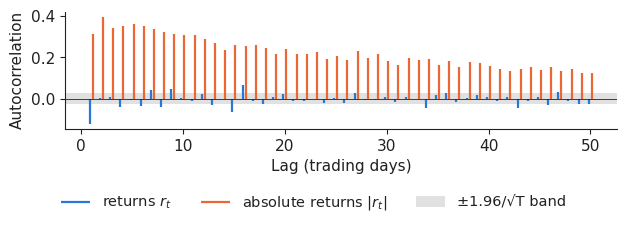

In [3]:
import matplotlib.dates as mdates
x = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
d = x[x.ticker == 'SP500'].set_index('date')[['open', 'high', 'low', 'close', 'adjclose']].dropna()
END = (d.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
d = d.loc[:END]; d = d[d.high > d.low]
gk = (0.5 * np.log(d.high / d.low) ** 2 - (2 * np.log(2) - 1) * np.log(d.close / d.open) ** 2).clip(lower=1e-8)
d['gk'] = gk; d['r'] = 100 * np.log(d.adjclose).diff(); d = d.dropna()
from statsmodels.tsa.stattools import acf
ar, aa = acf(d.r, nlags=50, fft=True)[1:], acf(d.r.abs(), nlags=50, fft=True)[1:]; band = 1.96 / np.sqrt(len(d))
show('acf.r1', 'rho_r(1)', round(float(ar[0]), 3)); show('acf.a1', 'rho_|r|(1)', round(float(aa[0]), 3)); show('acf.a50', 'rho_|r|(50)', round(float(aa[-1]), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.3)); k = np.arange(1, 51)
ax.vlines(k - .15, 0, ar, color=PAL['data'], lw=1.6, label='returns $r_t$'); ax.vlines(k + .15, 0, aa, color=PAL['model'], lw=1.6, label='absolute returns $|r_t|$')
ax.axhspan(-band, band, color='#8a8a8a', alpha=.25, lw=0, label='±1.96/√T band'); ax.axhline(0, color='#222222', lw=.6)
ax.set_xlabel('Lag (trading days)'); ax.set_ylabel('Autocorrelation'); legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('acf_abs.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()